# 11 · Ternary SLLE: benzene + water + ethanol with SAFT-γ Mie

**Real-mixture calculation.** Run top to bottom. Model parameters and pure-component data are identified explicitly. These are model predictions, not a fit or an experimental validation of SLLE. See the [course index](../tutorials.md).

<a class="md-button" href="11_ternary_slle_saft.ipynb" download>Download notebook</a>


At T=278 K and P=101325 Pa, compute a **benzene(s)+aqueous liquid+organic
liquid** flash and its tie triangle. The three-phase compositions are fixed at
this T/P while different feeds inside the triangle change the phase amounts.
Unlike the binary invariant, a ternary can have a finite three-phase composition
region at fixed T/P. Use unchanged bundled SAFT parameters and the same measured
benzene fusion data as notebook 10. No Margules model, surrogate γ, or artificial
fusion properties are used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import SAFTgammaMie
from thermoweave.equilibrium.reduced_held import ReducedChart, ReducedHELD, Solid
from _support import COMPONENTS, DATA, solid_gibbs, held_settings, check_flash, phase_table, phase_label
np.set_printoptions(precision=9, suppress=True)

In [2]:
names = ['benzene', 'water', 'ethanol']
T, P = 278., 101325.
assert T > max(COMPONENTS[n]['melting_temperature_K'] for n in ['water', 'ethanol'])
model = SAFTgammaMie.from_smiles({n: COMPONENTS[n]['smiles'] for n in names}, pressure_Pa=P)
chart = ReducedChart.build(np.zeros(3), [COMPONENTS[n]['molar_mass_g_mol'] for n in names])
solid = Solid('benzene(s)', [1., 0., 0.], solid_gibbs(T))
settings = held_settings()
print('Solid G/RT:', solid.gibbs)
print('Parameter source:', DATA['saft_parameters'])

def flash(feed):
    return ReducedHELD(model, T, chart, settings, solids=[solid]).flash(feed)

feed = np.array([0.66, 0.27, 0.07])  # one mole, order: benzene / water / ethanol
result = flash(feed)
assert result.phase_kinds.count('liquid') == 2 and 'benzene(s)' in result.phase_kinds
print(phase_table(result, names))
print('Independent physical checks:', check_flash(model, T, feed, result))

SAFT-gamma-Mie automatic assignment: benzene
  SMILES: c1ccccc1
  Formula: C6H6
  Groups: {'aCH': 6}
  Atom-labelled SMILES (labels are 1-based): [cH:1]1[cH:2][cH:3][cH:4][cH:5][cH:6]1
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  aCH x6:
    atoms 1:C(H1)
    atoms 2:C(H1)
    atoms 3:C(H1)
    atoms 4:C(H1)
    atoms 5:C(H1)
    atoms 6:C(H1)
    rule: aromatic CH in a six-membered ring; SMARTS [c;H1;r6]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 6/6 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


SAFT-gamma-Mie automatic assignment: water
  SMILES: O
  Formula: H2O
  Groups: {'H2O': 1}
  Atom-labelled SMILES (labels are 1-based): [OH2:1]
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  H2O x1:
    atoms 1:O(H2)
    rule: whole water molecule; SMARTS [O;H2;X2]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 1/1 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


SAFT-gamma-Mie automatic assignment: ethanol
  SMILES: CCO
  Formula: C2H6O
  Groups: {'CH2OH': 1, 'CH3': 1}
  Atom-labelled SMILES (labels are 1-based): [CH3:1][CH2:2][OH:3]
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  CH2OH x1:
    atoms 2:C(H2), 3:O(H1)
    rule: primary alcohol carbon plus hydroxyl; SMARTS [C;!R;H2;X4]-[O;H1;X2]
    parameters: 10.1021/acs.jced.0c00746
  CH3 x1:
    atoms 1:C(H3)
    rule: acyclic saturated methyl carbon; SMARTS [C;!R;H3;X4]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 3/3 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


Solid G/RT: -0.010568249090168734
Parameter source: Bundled Haslam et al. (2020) database, unchanged. All unlike dispersion pairs present. Published absence of aCH-CH2OH association is kept (no invented hydrogen-bond interaction).


[{'phase': 'liquid', 'mole_fraction_of_total': 0.2923910821425697, 'mass_fraction_of_total': 0.38008655045483736, 'x_benzene': 0.983566178222163, 'x_water': 0.0019301827160139156, 'x_ethanol': 0.014503639061823151}, {'phase': 'liquid', 'mole_fraction_of_total': 0.3357421350658192, 'mass_fraction_of_total': 0.13289355237124664, 'x_benzene': 0.0016299354236432911, 'x_water': 0.8025076499085195, 'x_ethanol': 0.19586241466783702}, {'phase': 'benzene(s)', 'mole_fraction_of_total': 0.371866782791611, 'mass_fraction_of_total': 0.4870198971739161, 'x_benzene': 1.0, 'x_water': 0.0, 'x_ethanol': 0.0}]
Independent physical checks: {'species_balance_error_mol': 2.19824158875781e-14, 'liquid_mu_error_over_RT': 9.373647691379716e-13, 'solid_saturation_error_over_RT': np.float64(9.32252539054268e-13), 'gibbs_reconstruction_error_over_RT': np.float64(2.6423307986078726e-14), 'phase_mole_fractions': [0.2923910821425854, 0.3357421350658372, 0.371866782791631], 'phase_mass_fractions': [0.3800865504548373

## Check the chemical potentials and material balances
For both liquids, $\mu_i/(RT)=\ln(x_i\gamma_i)$ in this gauge. All three species
have equal chemical potentials between the two liquids. Benzene in either liquid
also equals its solid potential. Reconstruct the feed with **phase mole fractions**;
the solver's `mass_fractions` are distinct and are printed separately.

In [3]:
X = np.asarray(result.mole_fractions)
liquid_ids = [i for i,k in enumerate(result.phase_kinds) if k == 'liquid']
mu = np.array([np.log(X[i])+model.ln_activity_coefficients(T, X[i]) for i in liquid_ids])
beta = np.array([n.sum() for n in result.phases])/feed.sum()
print('Liquid chemical potentials / RT:', mu)
print('Solid benzene potential / RT:', solid.gibbs)
print('Phase mole fractions:', beta)
print('Phase mass fractions:', result.mass_fractions)
np.testing.assert_allclose(mu[0], mu[1], atol=5e-7)
np.testing.assert_allclose(mu[:,0], solid.gibbs, atol=5e-7)
np.testing.assert_allclose(beta @ X, feed, atol=5e-8)

Liquid chemical potentials / RT: [[-0.010568249 -0.151045792 -0.950421242]
 [-0.010568249 -0.151045792 -0.950421242]]
Solid benzene potential / RT: -0.010568249090168734
Phase mole fractions: [0.292391082 0.335742135 0.371866783]
Phase mass fractions: [0.38008655  0.132893552 0.487019897]


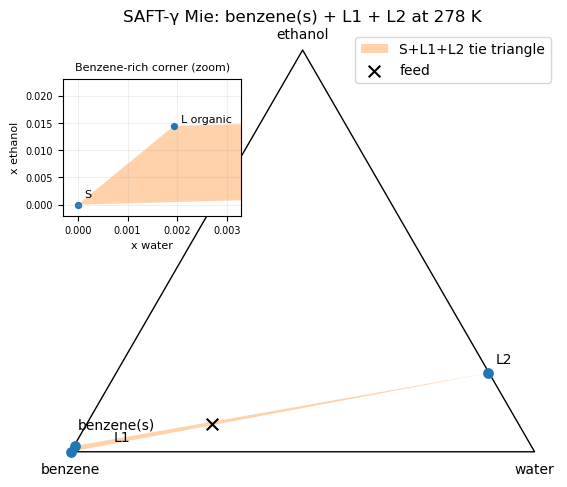

In [4]:
from _support import ternary_plot
fig, ax = ternary_plot(result, feed, 'SAFT-γ Mie: benzene(s) + L1 + L2 at 278 K')
plt.show()

## Move the feed inside the predicted three-phase triangle
Generate two different feeds as convex combinations of the **computed** phase
compositions, then flash them independently. This checks the lever rule and
that the phase vertices remain fixed; it does not insert those vertices into
the solver as prescribed phases.

In [5]:
reference = np.array(sorted(result.mole_fractions, key=lambda x: x[0]))
for weights in [np.array([.2,.5,.3]), np.array([.5,.3,.2])]:
    new_feed = weights @ X
    answer = flash(new_feed)
    print('Feed:', new_feed, '; phases:', phase_label(answer))
    print(check_flash(model, T, new_feed, answer))
    assert answer.phase_kinds.count('liquid') == 2 and 'benzene(s)' in answer.phase_kinds
    vertices = np.array(sorted(answer.mole_fractions, key=lambda x: x[0]))
    np.testing.assert_allclose(vertices, reference, atol=2e-6)

Feed: [0.497528203 0.401639861 0.100831935] ; phases: S+L1+L2
{'species_balance_error_mol': 1.1102230246251565e-16, 'liquid_mu_error_over_RT': 3.311032004127412e-13, 'solid_saturation_error_over_RT': np.float64(3.5049567415068594e-13), 'gibbs_reconstruction_error_over_RT': np.float64(1.5737411374061594e-14), 'phase_mole_fractions': [0.20000000000261128, 0.49999999999996525, 0.29999999999742344], 'phase_mass_fractions': [0.3055793598368087, 0.23261820955342974, 0.46180243060976156]}


Feed: [0.69227207  0.241717386 0.066010544] ; phases: S+L1+L2
{'species_balance_error_mol': 5.551115123125783e-17, 'liquid_mu_error_over_RT': 4.4185800851526125e-12, 'solid_saturation_error_over_RT': np.float64(4.403253803242357e-12), 'gibbs_reconstruction_error_over_RT': np.float64(1.1796119636642288e-15), 'phase_mole_fractions': [0.49999999998177097, 0.30000000000030114, 0.20000000001792778], 'phase_mass_fractions': [0.6306391048914546, 0.11521574457656425, 0.25414515053198106]}


## Survey the surrounding phase behaviour
A coarse feed lattice illustrates L, L1+L2 and solid-containing assemblages.
The S+L1+L2 region can be thin, so add the independently flashed interior
feeds above and draw its computed tie triangle. The dots are a **coarse survey**,
not a resolved binodal curve. Increase the resolution for a detailed diagram;
do not interpolate uncertified flashes into a claimed boundary.

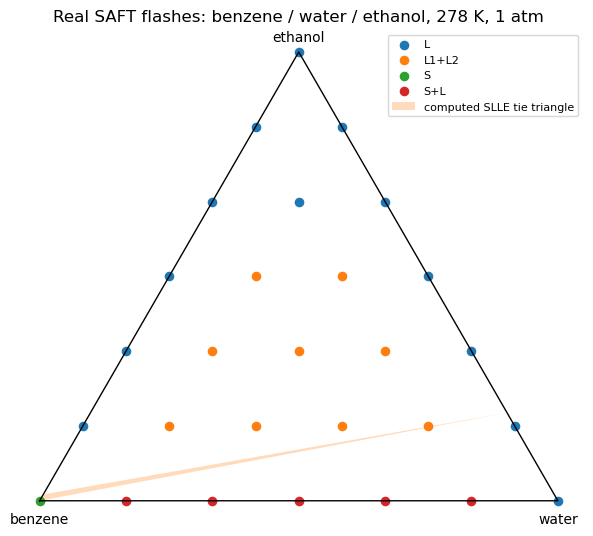

Certified feeds: 28 ; unresolved feeds: 0


In [6]:
from _support import ternary_axes
from matplotlib.patches import Polygon
resolution = 6
feeds, labels, unresolved = [], [], []
for i in range(resolution+1):
    for j in range(resolution+1-i):
        z = np.array([i, j, resolution-i-j], dtype=float)/resolution
        answer = flash(z)
        if answer.converged and answer.certified:
            check_flash(model, T, z, answer)
            feeds.append(z); labels.append(phase_label(answer))
        else:
            unresolved.append(z)
fig, ax = plt.subplots(figsize=(7.5,5.5)); corners = ternary_axes(ax)
feeds = np.asarray(feeds); labels = np.asarray(labels)
for label in sorted(set(labels)):
    xy = feeds[labels == label] @ corners
    ax.scatter(xy[:,0],xy[:,1],s=35,label=label)
xy = X @ corners
ax.add_patch(Polygon(xy,closed=True,facecolor='tab:orange',alpha=.28,label='computed SLLE tie triangle'))
if unresolved:
    xy = np.asarray(unresolved) @ corners
    ax.scatter(xy[:,0],xy[:,1],marker='x',color='black',label='uncertified: refine')
ax.set_title('Real SAFT flashes: benzene / water / ethanol, 278 K, 1 atm')
ax.legend(fontsize=8,loc='upper right');fig.tight_layout();plt.show()
print('Certified feeds:', len(feeds), '; unresolved feeds:', len(unresolved))

**Try:** set T=278.5 K and inspect the current feed's flash before applying
the three-phase assertions. The feed may leave the SLLE region even when
another three-phase region exists at that temperature. Select a new feed from
the new computed phase diagram; do not adjust fusion properties to force a
phase count. Notebook 12 uses the same components and measured solid data with
COSMO-RS and its own predicted three-phase conditions. No experimental SLLE
agreement is claimed.